## Discovery of Neptune

### News:

Night of September 23-24, 1846. 

On the night of Sept. 23-24, 1846, astronomers discovered Neptune, the eighth planet orbiting around the Sun. The discovery was made based on mathematical calculations of its predicted position due to observed perturbations in the orbit of the planet Uranus. The discovery was made using a telescope since Neptune is too faint to be visible to the naked eye, owing to its great distance from the Sun.

With the 1781 discovery of Uranus, the number of known planets in the solar system grew to seven. As astronomers continued to observe the newly discovered planet, they noticed irregularities in its orbit that Newton’s law of universal gravitation could not fully explain.

### Perturbation Theory

Perturbation theory uses mathematical methods to approximate solutions to problems that cannot be solved exactly, starting from the exact solution of a simpler related case. For example, the orbit of a planet around the Sun can be treated as a two body problem, while the influence of other planets is considered a perturbation that causes variations in eccentricity, orbital plane oscillations, or the precision of the perihelion.

These variations matched observations for all planets except for Mercury, whose perihelion advanced more than predicted. This anomaly was first attributed to a hypothetical planet near the Sun but was later explained by Einstein's theory of relativity.



https://www.nasa.gov/history/175-years-ago-astronomers-discover-neptune-the-eighth-planet/

https://www.historyofinformation.com/detail.php?id=4004

https://arxiv.org/html/2405.06310v1#S2



Celestial Mechanics greatly motivated the advances of perturbation
 theories as witnessed by the discovery of Neptune: its position was theoretically predicted by
 John Adams and by Jean Urbain Leverrier on the basis of perturbative computations; following
 the suggestion provided by the theoretical investigations, Neptune was finally discovered on 23
 September 1846 by the astronomer Johann Gottfried Galle.

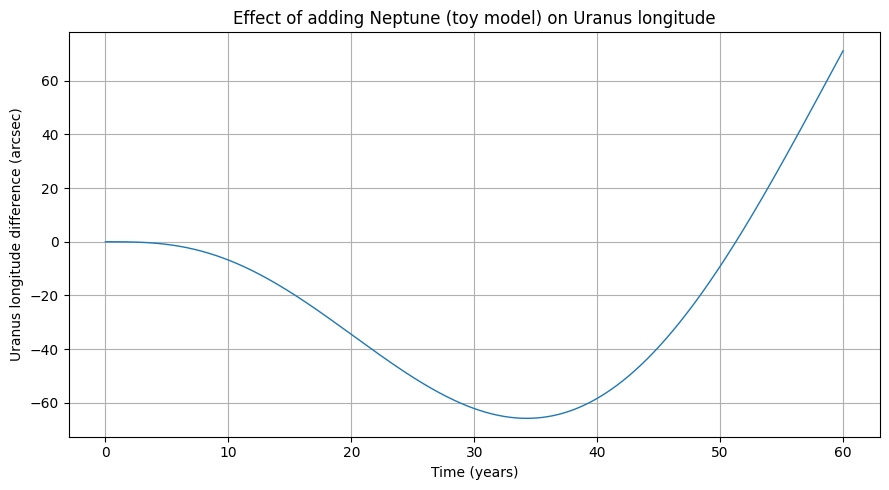

Saved residuals.png (toy model). Peak residual (arcsec): 71.1132783744045


In [1]:
"""
neptune_demo.py
Simple symplectic N-body demo to show Uranus longitude residuals caused by Neptune.
Usage: python neptune_demo.py
Outputs: residuals.png and data files.
"""

import numpy as np
import matplotlib.pyplot as plt

# Physical constants
G = 6.67430e-11           # m^3 kg^-1 s^-2
AU = 1.495978707e11       # m
DAY = 86400.0
yr = 365.25*DAY

# Masses (kg)
M_sun = 1.98847e30
m_jup = 1.89813e27
m_sat = 5.6834e26
m_ura = 8.6810e25
m_nep = 1.02413e26

# Semi-major axes (AU) (approx)
a_jup = 5.2044
a_sat = 9.5826
a_ura = 19.201
a_nep = 30.047

# Convert to meters
masses_base = {
    'Sun': M_sun,
    'Jupiter': m_jup,
    'Saturn': m_sat,
    'Uranus': m_ura,
    'Neptune': m_nep
}
a_base = {
    'Jupiter': a_jup*AU,
    'Saturn': a_sat*AU,
    'Uranus': a_ura*AU,
    'Neptune': a_nep*AU
}

def circular_velocity(mu, a):
    return np.sqrt(mu/a)

def init_system(include_neptune=True):
    # Order bodies: Sun, Jupiter, Saturn, Uranus, (Neptune)
    bodies = ['Sun','Jupiter','Saturn','Uranus']
    if include_neptune:
        bodies.append('Neptune')
    N = len(bodies)
    m = np.array([masses_base[name] for name in bodies])
    pos = np.zeros((N,3))
    vel = np.zeros((N,3))
    # Put Sun at origin; place planets on x-axis at t=0, velocities in +y for circular motion.
    pos[0,:] = 0.0
    for i,name in enumerate(bodies[1:], start=1):
        r = a_base[name]
        pos[i,0] = r
        mu = G*(M_sun + masses_base[name])  # approx
        v = circular_velocity(mu, r)
        vel[i,1] = v
        # Give Sun recoil so total momentum = 0
        vel[0] -= (m[i]/m[0]) * vel[i]
    return bodies, m, pos, vel

def accelerations(positions, masses):
    N = len(masses)
    a = np.zeros_like(positions)
    for i in range(N):
        for j in range(N):
            if i == j: continue
            rvec = positions[j] - positions[i]
            r = np.linalg.norm(rvec)
            a[i] += G * masses[j] * rvec / (r**3 + 1e-30)
    return a

def leapfrog_step(pos, vel, masses, dt):
    # kick-drift-kick (velocity Verlet form)
    a = accelerations(pos, masses)
    vel_half = vel + 0.5*dt*a
    pos_new = pos + dt*vel_half
    a_new = accelerations(pos_new, masses)
    vel_new = vel_half + 0.5*dt*a_new
    return pos_new, vel_new

def orbital_longitude(vec):
    # longitude in plane: atan2(y,x)
    return np.arctan2(vec[1], vec[0])

def run_sim(include_neptune, Tyears=50.0, dt_days=5.0):
    bodies, m, pos, vel = init_system(include_neptune=include_neptune)
    dt = dt_days * DAY
    steps = int(Tyears*yr/dt)
    times = np.linspace(0, Tyears*yr, steps)
    idx_ura = bodies.index('Uranus')
    lon = np.zeros(steps)
    for k in range(steps):
        lon[k] = orbital_longitude(pos[idx_ura])
        pos, vel = leapfrog_step(pos, vel, m, dt)
    # unwrap longitudes to be continuous
    lon = np.unwrap(lon)
    return times/yr, lon, bodies

if True:
    # Run both sims
    Tyears = 60.0
    times1, lon_no_nep, bodies1 = run_sim(include_neptune=False, Tyears=Tyears, dt_days=3.0)
    times2, lon_with_nep, bodies2 = run_sim(include_neptune=True, Tyears=Tyears, dt_days=3.0)

    # Interpolate to common timegrid (they share same grid here)
    residual = lon_with_nep - lon_no_nep

    # Convert residual (radians) to arcseconds:
    residual_arcsec = residual * (180.0/np.pi) * 3600.0

    plt.figure(figsize=(9,5))
    plt.plot(times1, residual_arcsec, lw=1)
    plt.xlabel("Time (years)")
    plt.ylabel("Uranus longitude difference (arcsec)")
    plt.title("Effect of adding Neptune (toy model) on Uranus longitude")
    plt.grid(True)
    plt.tight_layout()
    plt.savefig("residuals.png", dpi=150)
    plt.show()
    print("Saved residuals.png (toy model). Peak residual (arcsec):", np.max(np.abs(residual_arcsec)))


In [4]:
# discovery_orbits.py
import rebound
from astroquery.jplhorizons import Horizons
import numpy as np
import matplotlib.pyplot as plt

def get_orbit(name, epoch):
    """Safely fetch orbital elements from JPL Horizons"""
    obj = Horizons(id=name, location='@sun', epochs=epoch, id_type='majorbody')
    try:
        el = obj.elements()
    except Exception as e:
        print(f"Warning: Could not retrieve elements for {name}: {e}")
        return None
    return el

epoch = 2451545.0  # J2000.0 epoch

# Create REBOUND simulation
sim = rebound.Simulation()
sim.units = ('AU', 'yr', 'Msun')
sim.add(m=1.0)  # Sun

bodies = ['jupiter', 'saturn', 'uranus', 'neptune']

for b in bodies:
    el = get_orbit(b, epoch)
    if el is None:
        continue
    a = el['a'][0]          # Semi-major axis [AU]
    e = el['e'][0]
    inc = np.deg2rad(el['incl'][0])
    Omega = np.deg2rad(el['Omega'][0])
    omega = np.deg2rad(el['w'][0])
    M = np.deg2rad(el['M'][0])
    sim.add(a=a, e=e, inc=inc, Omega=Omega, omega=omega, M=M, hash=b)

sim.move_to_com()

# Integrate forward
times = np.linspace(0, 50, 500)  # 50 years
positions = {b: [] for b in bodies}

for t in times:
    sim.integrate(t)
    for b in bodies:
        p = sim.particles[b]
        positions[b].append([p.x, p.y])

# Plot orbits
plt.figure(figsize=(7,7))
for b in bodies:
    arr = np.array(positions[b])
    plt.plot(arr[:,0], arr[:,1], label=b.capitalize())
plt.scatter(0, 0, color='orange', s=100, label='Sun')
plt.legend()
plt.xlabel('x [AU]')
plt.ylabel('y [AU]')
plt.axis('equal')
plt.title("Planetary Orbits (JPL Initial Conditions)")
plt.show()


  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        5  Jupiter Barycenter                                                   
      599  Jupiter                                                              
 
  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        6  Saturn Barycenter                                                    
      699  Saturn                                                               
 
  ID#      Name                               Designation  IAU/aliases/other   
  -------  ---------------------------------- -----------  ------------------- 
        7  Uranus Barycenter                                                    
      799  Uranus                                                               
 
  ID#      Name             

ParticleNotFound: Particle was not found in the simulation.

Simulating orbits...
Progress: 0/400
Progress: 100/400
Progress: 200/400
Progress: 300/400
Position arrays created. Shapes: [(400, 2), (400, 2), (400, 2), (400, 2)]
Creating animation...
Saving animation...
Saving frame 0/400
Saving frame 50/400
Saving frame 100/400
Saving frame 150/400
Saving frame 200/400
Saving frame 250/400
Saving frame 300/400
Saving frame 350/400
Animation saved successfully as planets.gif


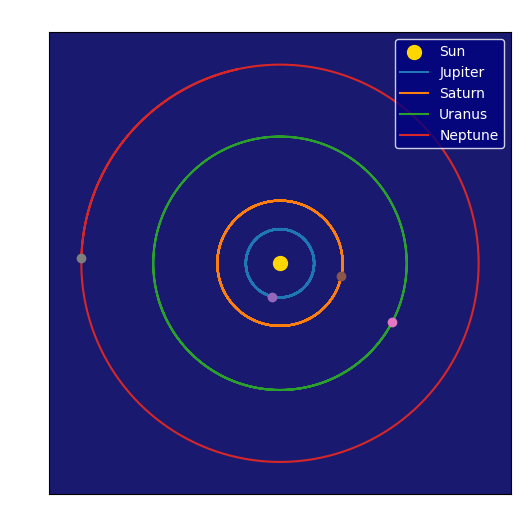

In [10]:
import rebound
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

# Define planets (semi-major axis in AU, period in years)
planets = {
    "Jupiter":  (5.2, 11.86),
    "Saturn":   (9.5, 29.46),
    "Uranus":  (19.2, 84.01),
    "Neptune": (30.1, 164.8),
}

sim = rebound.Simulation()
sim.units = ('AU', 'yr', 'Msun')
sim.add(m=1.0)  # Sun

for i, (name, (a, P)) in enumerate(planets.items()):
    M = 2*np.pi*np.random.random()  # random mean anomaly
    sim.add(a=a, e=0, inc=0, omega=0, Omega=0, M=M, hash=name)

sim.move_to_com()

# Record positions - use fewer frames for stability
times = np.linspace(0, 200, 400)  # Reduced frames
positions = {name: [] for name in planets}

print("Simulating orbits...")
for i, t in enumerate(times):
    sim.integrate(t)
    for name in planets:
        p = sim.particles[name]
        positions[name].append([p.x, p.y])
    if i % 100 == 0:  # Progress indicator
        print(f"Progress: {i}/{len(times)}")

# Convert to arrays and verify data
positions = {k: np.array(v) for k,v in positions.items()}
print(f"Position arrays created. Shapes: {[v.shape for v in positions.values()]}")

# Create animation
fig, ax = plt.subplots(figsize=(6,6))
ax.set_facecolor("midnightblue")
ax.set_xlim(-35, 35)
ax.set_ylim(-35, 35)
ax.set_aspect("equal")
ax.set_title("Simplified Coplanar Planetary Orbits", color="white")
ax.tick_params(colors="white")
ax.scatter(0, 0, color="gold", s=100, label="Sun")

lines = {name: ax.plot([], [], label=name, lw=1.5)[0] for name in planets}
points = {name: ax.plot([], [], "o", ms=6)[0] for name in planets}
ax.legend(facecolor="navy", edgecolor="white", labelcolor="white", loc="upper right")

def init():
    for name in planets:
        lines[name].set_data([], [])
        points[name].set_data([], [])
    return list(lines.values()) + list(points.values())

def update(frame):
    # Ensure frame doesn't exceed array bounds
    frame = min(frame, len(times) - 1)
    
    for name in planets:
        # Show orbit trail
        lines[name].set_data(positions[name][:frame, 0], positions[name][:frame, 1])
        # Current position
        points[name].set_data([positions[name][frame, 0]], [positions[name][frame, 1]])
    
    return list(lines.values()) + list(points.values())

# Create animation
print("Creating animation...")
ani = FuncAnimation(fig, update, frames=len(times), init_func=init, 
                   blit=True, interval=40, repeat=True)

# Save with progress callback
print("Saving animation...")
try:
    ani.save("planets.gif", writer="pillow", fps=25, progress_callback=lambda i, n: print(f"Saving frame {i}/{n}") if i % 50 == 0 else None)
    print("Animation saved successfully as planets.gif")
except Exception as e:
    print(f"Error saving animation: {e}")
    # Try alternative save method
    try:
        print("Trying alternative save method...")
        writer = animation.PillowWriter(fps=25)
        ani.save("planets_alt.gif", writer=writer)
        print("Animation saved successfully as planets_alt.gif")
    except Exception as e2:
        print(f"Alternative save also failed: {e2}")

plt.show()